In [38]:
#Importing all modules
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

import warnings
warnings.filterwarnings('ignore')
data=pd.read_csv("Recipe Review.csv")

In [39]:
pip install pandas xlrd

Note: you may need to restart the kernel to use updated packages.


In [40]:
data

,Unnamed: 0,recipe_number,recipe_code,recipe_name,comment_id,user_id,user_name,user_reputation,created_at,reply_count,thumbs_up,thumbs_down,stars,best_score,text
0,0,1,14299,Creamy White Chili,sp_aUSaElGf_14299_c_2G3aneMRgRMZwXqIHmSdXSG1hEM,u_9iFLIhMa8QaG,Jeri326,1,1665619889,0,0,0,5,527,"I tweaked it a little, removed onions because ..."
1,1,1,14299,Creamy White Chili,sp_aUSaElGf_14299_c_2FsPC83HtzCsQAtOxlbL6RcaPbY,u_Lu6p25tmE77j,Mark467,50,1665277687,0,7,0,5,724,Bush used to have a white chili bean and it ma...
2,2,1,14299,Creamy White Chili,sp_aUSaElGf_14299_c_2FPrSGyTv7PQkZq37j92r9mYGkP,u_s0LwgpZ8Jsqq,Barbara566,10,1664404557,0,3,0,5,710,I have a very complicated white chicken chili ...
3,3,1,14299,Creamy White Chili,sp_aUSaElGf_14299_c_2DzdSIgV9qNiuBaLoZ7JQaartoC,u_fqrybAdYjgjG,jeansch123,1,1661787808,2,2,0,0,581,"In your introduction, you mentioned cream chee..."
4,4,1,14299,Creamy White Chili,sp_aUSaElGf_14299_c_2DtZJuRQYeTFwXBoZRfRhBPEXjI,u_XXWKwVhKZD69,camper77,10,1664913823,1,7,0,0,820,Wonderful! I made this for a &#34;Chili/Stew&#...
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
18177,114,100,82745,Mamaw Emily’s Strawberry Cake,sp_aUSaElGf_82745_c_331352,u_1oKblS4ULpTAACUTILo0QlO5mrN,WhittierCA,1,1622717977,0,0,0,5,100,This Strawberry Cake has been a family favorit...
18178,115,100,82745,Mamaw Emily’s Strawberry Cake,sp_aUSaElGf_82745_c_204836,u_1oKY7CKLaFQpI3cBCVaxHXAEGbt,susieswan,1,1613036720,0,0,0,5,100,<p>I received endless compliments on this cake...
18179,116,100,82745,Mamaw Emily’s Strawberry Cake,sp_aUSaElGf_82745_c_301178,u_1oKXBAuHbMDi9nnriVAbJoPqpeQ,blajr,1,1622717844,0,0,0,5,100,This cake was delicious and so moist! I didn&#...
18180,117,100,82745,Mamaw Emily’s Strawberry Cake,sp_aUSaElGf_82745_c_180512,u_1oKVbnueXfnlmYWuYH8xJ0mFxNQ,cafritz,1,1622717233,0,0,0,5,100,I just made this too. It is wonderful. As fo...


In [41]:
df = pd.DataFrame(data)
df

,Unnamed: 0,recipe_number,recipe_code,recipe_name,comment_id,user_id,user_name,user_reputation,created_at,reply_count,thumbs_up,thumbs_down,stars,best_score,text
0,0,1,14299,Creamy White Chili,sp_aUSaElGf_14299_c_2G3aneMRgRMZwXqIHmSdXSG1hEM,u_9iFLIhMa8QaG,Jeri326,1,1665619889,0,0,0,5,527,"I tweaked it a little, removed onions because ..."
1,1,1,14299,Creamy White Chili,sp_aUSaElGf_14299_c_2FsPC83HtzCsQAtOxlbL6RcaPbY,u_Lu6p25tmE77j,Mark467,50,1665277687,0,7,0,5,724,Bush used to have a white chili bean and it ma...
2,2,1,14299,Creamy White Chili,sp_aUSaElGf_14299_c_2FPrSGyTv7PQkZq37j92r9mYGkP,u_s0LwgpZ8Jsqq,Barbara566,10,1664404557,0,3,0,5,710,I have a very complicated white chicken chili ...
3,3,1,14299,Creamy White Chili,sp_aUSaElGf_14299_c_2DzdSIgV9qNiuBaLoZ7JQaartoC,u_fqrybAdYjgjG,jeansch123,1,1661787808,2,2,0,0,581,"In your introduction, you mentioned cream chee..."
4,4,1,14299,Creamy White Chili,sp_aUSaElGf_14299_c_2DtZJuRQYeTFwXBoZRfRhBPEXjI,u_XXWKwVhKZD69,camper77,10,1664913823,1,7,0,0,820,Wonderful! I made this for a &#34;Chili/Stew&#...
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
18177,114,100,82745,Mamaw Emily’s Strawberry Cake,sp_aUSaElGf_82745_c_331352,u_1oKblS4ULpTAACUTILo0QlO5mrN,WhittierCA,1,1622717977,0,0,0,5,100,This Strawberry Cake has been a family favorit...
18178,115,100,82745,Mamaw Emily’s Strawberry Cake,sp_aUSaElGf_82745_c_204836,u_1oKY7CKLaFQpI3cBCVaxHXAEGbt,susieswan,1,1613036720,0,0,0,5,100,<p>I received endless compliments on this cake...
18179,116,100,82745,Mamaw Emily’s Strawberry Cake,sp_aUSaElGf_82745_c_301178,u_1oKXBAuHbMDi9nnriVAbJoPqpeQ,blajr,1,1622717844,0,0,0,5,100,This cake was delicious and so moist! I didn&#...
18180,117,100,82745,Mamaw Emily’s Strawberry Cake,sp_aUSaElGf_82745_c_180512,u_1oKVbnueXfnlmYWuYH8xJ0mFxNQ,cafritz,1,1622717233,0,0,0,5,100,I just made this too. It is wonderful. As fo...


In [42]:
df.head(5)

,Unnamed: 0,recipe_number,recipe_code,recipe_name,comment_id,user_id,user_name,user_reputation,created_at,reply_count,thumbs_up,thumbs_down,stars,best_score,text
0,0,1,14299,Creamy White Chili,sp_aUSaElGf_14299_c_2G3aneMRgRMZwXqIHmSdXSG1hEM,u_9iFLIhMa8QaG,Jeri326,1,1665619889,0,0,0,5,527,"I tweaked it a little, removed onions because ..."
1,1,1,14299,Creamy White Chili,sp_aUSaElGf_14299_c_2FsPC83HtzCsQAtOxlbL6RcaPbY,u_Lu6p25tmE77j,Mark467,50,1665277687,0,7,0,5,724,Bush used to have a white chili bean and it ma...
2,2,1,14299,Creamy White Chili,sp_aUSaElGf_14299_c_2FPrSGyTv7PQkZq37j92r9mYGkP,u_s0LwgpZ8Jsqq,Barbara566,10,1664404557,0,3,0,5,710,I have a very complicated white chicken chili ...
3,3,1,14299,Creamy White Chili,sp_aUSaElGf_14299_c_2DzdSIgV9qNiuBaLoZ7JQaartoC,u_fqrybAdYjgjG,jeansch123,1,1661787808,2,2,0,0,581,"In your introduction, you mentioned cream chee..."
4,4,1,14299,Creamy White Chili,sp_aUSaElGf_14299_c_2DtZJuRQYeTFwXBoZRfRhBPEXjI,u_XXWKwVhKZD69,camper77,10,1664913823,1,7,0,0,820,Wonderful! I made this for a &#34;Chili/Stew&#...


In [43]:
df.tail(5)

,Unnamed: 0,recipe_number,recipe_code,recipe_name,comment_id,user_id,user_name,user_reputation,created_at,reply_count,thumbs_up,thumbs_down,stars,best_score,text
18177,114,100,82745,Mamaw Emily’s Strawberry Cake,sp_aUSaElGf_82745_c_331352,u_1oKblS4ULpTAACUTILo0QlO5mrN,WhittierCA,1,1622717977,0,0,0,5,100,This Strawberry Cake has been a family favorit...
18178,115,100,82745,Mamaw Emily’s Strawberry Cake,sp_aUSaElGf_82745_c_204836,u_1oKY7CKLaFQpI3cBCVaxHXAEGbt,susieswan,1,1613036720,0,0,0,5,100,<p>I received endless compliments on this cake...
18179,116,100,82745,Mamaw Emily’s Strawberry Cake,sp_aUSaElGf_82745_c_301178,u_1oKXBAuHbMDi9nnriVAbJoPqpeQ,blajr,1,1622717844,0,0,0,5,100,This cake was delicious and so moist! I didn&#...
18180,117,100,82745,Mamaw Emily’s Strawberry Cake,sp_aUSaElGf_82745_c_180512,u_1oKVbnueXfnlmYWuYH8xJ0mFxNQ,cafritz,1,1622717233,0,0,0,5,100,I just made this too. It is wonderful. As fo...
18181,118,100,82745,Mamaw Emily’s Strawberry Cake,sp_aUSaElGf_82745_c_262637,u_1oKW6W12cOLxiMzjA7j8nTqwFWG,nopalito,1,1622717625,0,1,0,5,193,"OMG, you must make this cake. I made it for my..."


In [44]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 18182 entries, 0 to 18181
Data columns (total 15 columns):
 #   Column           Non-Null Count  Dtype
---  ------           --------------  -----
 0   Unnamed: 0       18182 non-null  int64
 1   recipe_number    18182 non-null  int64
 2   recipe_code      18182 non-null  int64
 3   recipe_name      18182 non-null  str  
 4   comment_id       18182 non-null  str  
 5   user_id          18182 non-null  str  
 6   user_name        18182 non-null  str  
 7   user_reputation  18182 non-null  int64
 8   created_at       18182 non-null  int64
 9   reply_count      18182 non-null  int64
 10  thumbs_up        18182 non-null  int64
 11  thumbs_down      18182 non-null  int64
 12  stars            18182 non-null  int64
 13  best_score       18182 non-null  int64
 14  text             18180 non-null  str  
dtypes: int64(10), str(5)
memory usage: 7.1 MB


In [45]:
df.shape

(18182, 15)

In [46]:
df.columns

Index(['Unnamed: 0', 'recipe_number', 'recipe_code', 'recipe_name',
       'comment_id', 'user_id', 'user_name', 'user_reputation', 'created_at',
       'reply_count', 'thumbs_up', 'thumbs_down', 'stars', 'best_score',
       'text'],
      dtype='str')

In [47]:
df.describe()

,Unnamed: 0,recipe_number,recipe_code,user_reputation,created_at,reply_count,thumbs_up,thumbs_down,stars,best_score
count,18182.000000,18182.000000,18182.000000,18182.000000,1.818200e+04,18182.000000,18182.000000,18182.000000,18182.000000,18182.000000
mean,121.465295,38.689363,21773.667253,2.159608,1.623710e+09,0.014630,1.089264,0.549335,4.288802,153.162138
std,116.747893,29.786647,23965.109637,10.014666,5.468697e+06,0.137974,4.201004,3.470124,1.544786,141.075316
min,0.000000,1.000000,386.000000,0.000000,1.613035e+09,0.000000,0.000000,0.000000,0.000000,0.000000
25%,45.000000,12.000000,6086.000000,1.000000,1.622717e+09,0.000000,0.000000,0.000000,5.000000,100.000000
50%,91.000000,33.000000,14600.000000,1.000000,1.622718e+09,0.000000,0.000000,0.000000,5.000000,100.000000
75%,150.000000,64.000000,33121.000000,1.000000,1.622718e+09,0.000000,0.000000,0.000000,5.000000,100.000000
max,724.000000,100.000000,191775.000000,520.000000,1.665756e+09,3.000000,106.000000,126.000000,5.000000,946.000000


In [48]:
print("\nColumns:")
print(df.columns.tolist())


Columns:
['Unnamed: 0', 'recipe_number', 'recipe_code', 'recipe_name', 'comment_id', 'user_id', 'user_name', 'user_reputation', 'created_at', 'reply_count', 'thumbs_up', 'thumbs_down', 'stars', 'best_score', 'text']


In [49]:
#Remove the extra index column if present
df=df.drop(columns=[""],errors="ignore")
df=df.loc[:,~df.columns.str.match(r"^Unnamed")]
df.head(6)

,recipe_number,recipe_code,recipe_name,comment_id,user_id,user_name,user_reputation,created_at,reply_count,thumbs_up,thumbs_down,stars,best_score,text
0,1,14299,Creamy White Chili,sp_aUSaElGf_14299_c_2G3aneMRgRMZwXqIHmSdXSG1hEM,u_9iFLIhMa8QaG,Jeri326,1,1665619889,0,0,0,5,527,"I tweaked it a little, removed onions because ..."
1,1,14299,Creamy White Chili,sp_aUSaElGf_14299_c_2FsPC83HtzCsQAtOxlbL6RcaPbY,u_Lu6p25tmE77j,Mark467,50,1665277687,0,7,0,5,724,Bush used to have a white chili bean and it ma...
2,1,14299,Creamy White Chili,sp_aUSaElGf_14299_c_2FPrSGyTv7PQkZq37j92r9mYGkP,u_s0LwgpZ8Jsqq,Barbara566,10,1664404557,0,3,0,5,710,I have a very complicated white chicken chili ...
3,1,14299,Creamy White Chili,sp_aUSaElGf_14299_c_2DzdSIgV9qNiuBaLoZ7JQaartoC,u_fqrybAdYjgjG,jeansch123,1,1661787808,2,2,0,0,581,"In your introduction, you mentioned cream chee..."
4,1,14299,Creamy White Chili,sp_aUSaElGf_14299_c_2DtZJuRQYeTFwXBoZRfRhBPEXjI,u_XXWKwVhKZD69,camper77,10,1664913823,1,7,0,0,820,Wonderful! I made this for a &#34;Chili/Stew&#...
5,1,14299,Creamy White Chili,sp_aUSaElGf_14299_c_2Do918IutExN0pWEOFMU4cbiT8v,u_BALTQJIvWtYr,nikhita,1,1661354351,0,3,1,5,518,amazing! my boyfriend loved it so much! going ...


In [ ]:
#Convert columns to numeric where possible
for col in df.columns:
    df[col]= pd.to_numeric(df[col],errors="coerce")

In [ ]:
#Promote the first data row to column headers, then remove that row
data.columns=data.iloc[0].astype(str).str.strip()
df=data.iloc[1:].reset_index(drop=True)

In [95]:
df.info()   #Checking after updation

<class 'pandas.DataFrame'>
RangeIndex: 18182 entries, 0 to 18181
Data columns (total 14 columns):
 #   Column           Non-Null Count  Dtype
---  ------           --------------  -----
 0   recipe_number    18182 non-null  int64
 1   recipe_code      18182 non-null  int64
 2   recipe_name      18182 non-null  str  
 3   comment_id       18182 non-null  str  
 4   user_id          18182 non-null  str  
 5   user_name        18182 non-null  str  
 6   user_reputation  18182 non-null  int64
 7   created_at       18182 non-null  int64
 8   reply_count      18182 non-null  int64
 9   thumbs_up        18182 non-null  int64
 10  thumbs_down      18182 non-null  int64
 11  stars            18182 non-null  int64
 12  best_score       18182 non-null  int64
 13  text             18182 non-null  str  
dtypes: int64(9), str(5)
memory usage: 7.0 MB


In [96]:
df.shape #Checking after updation

(18182, 14)

In [51]:
print(df.dtypes)

recipe_number      int64
recipe_code        int64
recipe_name          str
comment_id           str
user_id              str
user_name            str
user_reputation    int64
created_at         int64
reply_count        int64
thumbs_up          int64
thumbs_down        int64
stars              int64
best_score         int64
text                 str
dtype: object


In [52]:
#Handling missing values
df.isnull().sum()

recipe_number      0
recipe_code        0
recipe_name        0
comment_id         0
user_id            0
user_name          0
user_reputation    0
created_at         0
reply_count        0
thumbs_up          0
thumbs_down        0
stars              0
best_score         0
text               2
dtype: int64

In [53]:
df.isnull()

,recipe_number,recipe_code,recipe_name,comment_id,user_id,user_name,user_reputation,created_at,reply_count,thumbs_up,thumbs_down,stars,best_score,text
0,False,False,False,False,False,False,False,False,False,False,False,False,False,False
1,False,False,False,False,False,False,False,False,False,False,False,False,False,False
2,False,False,False,False,False,False,False,False,False,False,False,False,False,False
3,False,False,False,False,False,False,False,False,False,False,False,False,False,False
4,False,False,False,False,False,False,False,False,False,False,False,False,False,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
18177,False,False,False,False,False,False,False,False,False,False,False,False,False,False
18178,False,False,False,False,False,False,False,False,False,False,False,False,False,False
18179,False,False,False,False,False,False,False,False,False,False,False,False,False,False
18180,False,False,False,False,False,False,False,False,False,False,False,False,False,False


In [54]:
#Handling duplicate values
df.duplicated().sum()

np.int64(0)

In [55]:
df.duplicated()

0        False
1        False
2        False
3        False
4        False
         ...  
18177    False
18178    False
18179    False
18180    False
18181    False
Length: 18182, dtype: bool

<Axes: >

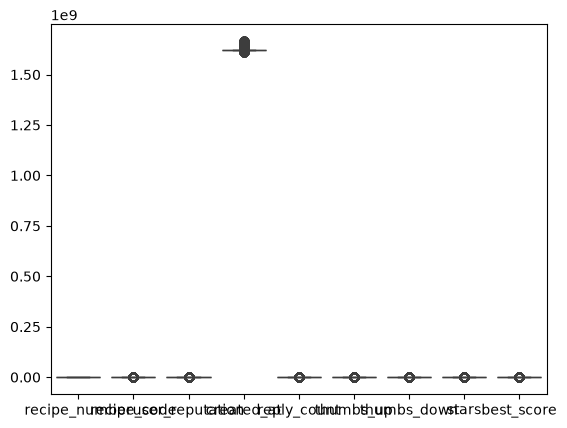

In [56]:
#Visualising the data and handling the outliers
sns.boxplot(data=df)

In [57]:
# Function to apply IQR method to fix outliers
def fix_outliers_iqr(df):
    num = df.select_dtypes(include='number').columns
    for col in num:
        Q1 = df[col].quantile(0.25)
        Q3 = df[col].quantile(0.75)
        IQR = Q3 - Q1
        lower_bound = Q1 - 1.5 * IQR
        upper_bound = Q3 + 1.5 * IQR
        df[col] = df[col].clip(
            lower=lower_bound,
            upper=upper_bound
        )
    return df

In [58]:
df1=fix_outliers_iqr(df)
df1

,recipe_number,recipe_code,recipe_name,comment_id,user_id,user_name,user_reputation,created_at,reply_count,thumbs_up,thumbs_down,stars,best_score,text
0,1,14299.0,Creamy White Chili,sp_aUSaElGf_14299_c_2G3aneMRgRMZwXqIHmSdXSG1hEM,u_9iFLIhMa8QaG,Jeri326,1,1622719569,0,0,0,5,100,"I tweaked it a little, removed onions because ..."
1,1,14299.0,Creamy White Chili,sp_aUSaElGf_14299_c_2FsPC83HtzCsQAtOxlbL6RcaPbY,u_Lu6p25tmE77j,Mark467,1,1622719569,0,0,0,5,100,Bush used to have a white chili bean and it ma...
2,1,14299.0,Creamy White Chili,sp_aUSaElGf_14299_c_2FPrSGyTv7PQkZq37j92r9mYGkP,u_s0LwgpZ8Jsqq,Barbara566,1,1622719569,0,0,0,5,100,I have a very complicated white chicken chili ...
3,1,14299.0,Creamy White Chili,sp_aUSaElGf_14299_c_2DzdSIgV9qNiuBaLoZ7JQaartoC,u_fqrybAdYjgjG,jeansch123,1,1622719569,0,0,0,5,100,"In your introduction, you mentioned cream chee..."
4,1,14299.0,Creamy White Chili,sp_aUSaElGf_14299_c_2DtZJuRQYeTFwXBoZRfRhBPEXjI,u_XXWKwVhKZD69,camper77,1,1622719569,0,0,0,5,100,Wonderful! I made this for a &#34;Chili/Stew&#...
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
18177,100,73673.5,Mamaw Emily’s Strawberry Cake,sp_aUSaElGf_82745_c_331352,u_1oKblS4ULpTAACUTILo0QlO5mrN,WhittierCA,1,1622717977,0,0,0,5,100,This Strawberry Cake has been a family favorit...
18178,100,73673.5,Mamaw Emily’s Strawberry Cake,sp_aUSaElGf_82745_c_204836,u_1oKY7CKLaFQpI3cBCVaxHXAEGbt,susieswan,1,1622715841,0,0,0,5,100,<p>I received endless compliments on this cake...
18179,100,73673.5,Mamaw Emily’s Strawberry Cake,sp_aUSaElGf_82745_c_301178,u_1oKXBAuHbMDi9nnriVAbJoPqpeQ,blajr,1,1622717844,0,0,0,5,100,This cake was delicious and so moist! I didn&#...
18180,100,73673.5,Mamaw Emily’s Strawberry Cake,sp_aUSaElGf_82745_c_180512,u_1oKVbnueXfnlmYWuYH8xJ0mFxNQ,cafritz,1,1622717233,0,0,0,5,100,I just made this too. It is wonderful. As fo...


<Axes: >

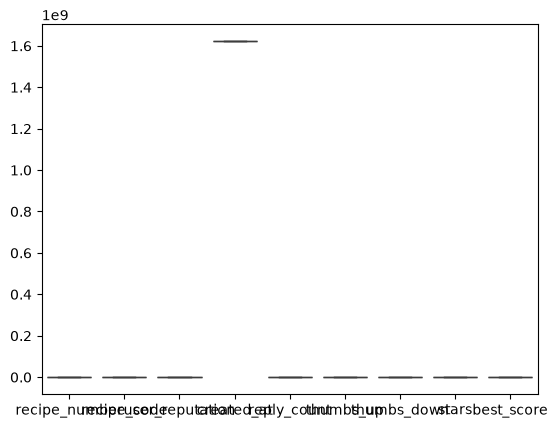

In [59]:
sns.boxplot(data=df1)

In [61]:
# Encoding - One Hot Encoder
from sklearn.preprocessing import OneHotEncoder
ohe_recipe = OneHotEncoder(
    sparse_output=False,
    handle_unknown='ignore'
)
recipe_encoded = ohe_recipe.fit_transform(df1[['recipe_name']])
recipe_df = pd.DataFrame(
    recipe_encoded,
    columns=ohe_recipe.get_feature_names_out(['recipe_name']),
    index=df1.index
)
df = pd.concat(
    [df1.drop('recipe_name', axis=1), recipe_df],
    axis=1
)
df

,recipe_number,recipe_code,comment_id,user_id,user_name,user_reputation,created_at,reply_count,thumbs_up,thumbs_down,...,recipe_name_Taco Lasagna,recipe_name_Tennessee Peach Pudding,recipe_name_Teriyaki Chicken Thighs,recipe_name_Traditional Lasagna,recipe_name_Twice-Baked Potato Casserole,recipe_name_Vegetarian Linguine,recipe_name_White Bean Chicken Chili,recipe_name_Winning Apple Crisp,recipe_name_Zucchini Cupcake,recipe_name_Zucchini Pizza Casserole
0,1,14299.0,sp_aUSaElGf_14299_c_2G3aneMRgRMZwXqIHmSdXSG1hEM,u_9iFLIhMa8QaG,Jeri326,1,1622719569,0,0,0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1,1,14299.0,sp_aUSaElGf_14299_c_2FsPC83HtzCsQAtOxlbL6RcaPbY,u_Lu6p25tmE77j,Mark467,1,1622719569,0,0,0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,1,14299.0,sp_aUSaElGf_14299_c_2FPrSGyTv7PQkZq37j92r9mYGkP,u_s0LwgpZ8Jsqq,Barbara566,1,1622719569,0,0,0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3,1,14299.0,sp_aUSaElGf_14299_c_2DzdSIgV9qNiuBaLoZ7JQaartoC,u_fqrybAdYjgjG,jeansch123,1,1622719569,0,0,0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4,1,14299.0,sp_aUSaElGf_14299_c_2DtZJuRQYeTFwXBoZRfRhBPEXjI,u_XXWKwVhKZD69,camper77,1,1622719569,0,0,0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
18177,100,73673.5,sp_aUSaElGf_82745_c_331352,u_1oKblS4ULpTAACUTILo0QlO5mrN,WhittierCA,1,1622717977,0,0,0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
18178,100,73673.5,sp_aUSaElGf_82745_c_204836,u_1oKY7CKLaFQpI3cBCVaxHXAEGbt,susieswan,1,1622715841,0,0,0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
18179,100,73673.5,sp_aUSaElGf_82745_c_301178,u_1oKXBAuHbMDi9nnriVAbJoPqpeQ,blajr,1,1622717844,0,0,0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
18180,100,73673.5,sp_aUSaElGf_82745_c_180512,u_1oKVbnueXfnlmYWuYH8xJ0mFxNQ,cafritz,1,1622717233,0,0,0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


In [66]:
# Encoding - Categorical Features
target_column = "stars"
categorical_columns = [
    column for column in ["user_name"]
    if column in df.columns
]
print("Categorical predictor columns:", categorical_columns)

Categorical predictor columns: ['user_name']


In [64]:
#Separate independent variables (x) and dependent variables (y)
X = df.drop(
    columns=[target_column, "stars"],
    errors="ignore"
)
y = df[target_column].astype(int)
print("Independent variables (X):", X.shape)
print("Dependent variable (y):", y.shape)
print("\nTarget classes:")
print(y.value_counts())

Independent variables (X): (18182, 112)
Dependent variable (y): (18182,)

Target classes:
stars
5    18182
Name: count, dtype: int64


Recipe Rating Distribution:
stars
5    18182
Name: count, dtype: int64

Unique Ratings:
[5]


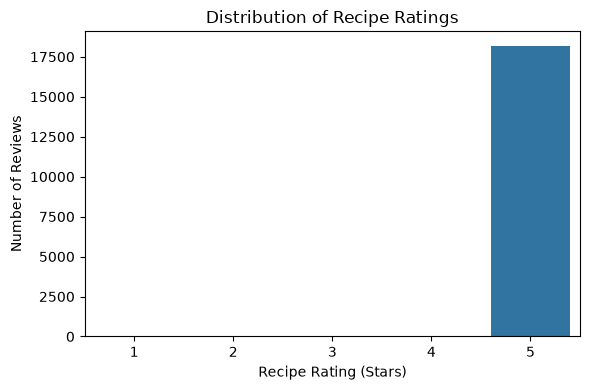

In [69]:
#Data Visualisation
#Visualization 1: Target class distribution
print("Recipe Rating Distribution:")
print(df['stars'].value_counts(dropna=False).sort_index())
print("\nUnique Ratings:")
print(df['stars'].unique())
plt.figure(figsize=(6, 4))
sns.countplot(
    data=df,
    x="stars",
    order=[1, 2, 3, 4, 5]
)
plt.title("Distribution of Recipe Ratings")
plt.xlabel("Recipe Rating (Stars)")
plt.ylabel("Number of Reviews")
plt.tight_layout()
plt.show()

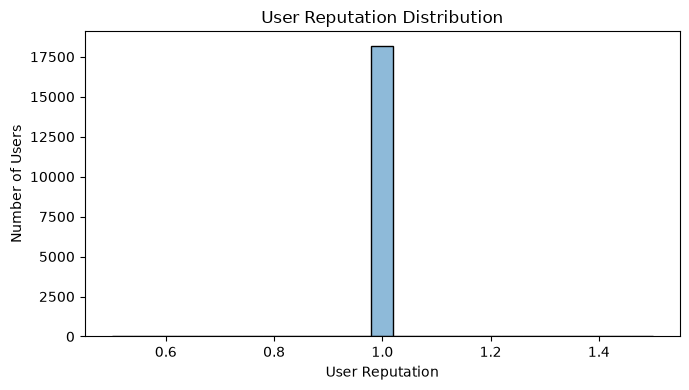

In [70]:
# Visualization 2: User Reputation Distribution
plt.figure(figsize=(7, 4))
sns.histplot(data=df, x="user_reputation", bins=25, kde=True)
plt.title("User Reputation Distribution")
plt.xlabel("User Reputation")
plt.ylabel("Number of Users")
plt.tight_layout()
plt.show()

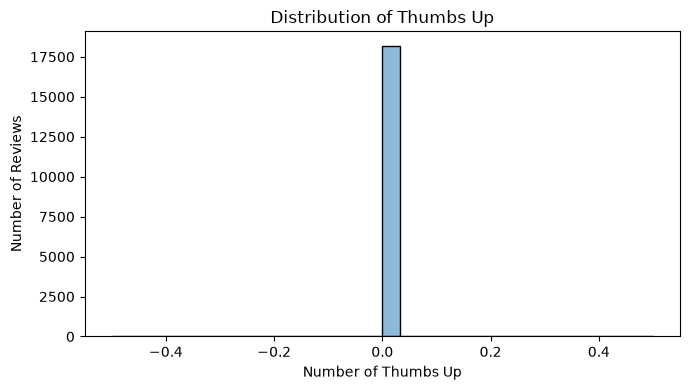

In [71]:
# Visualization 3: Thumbs Up Distribution
plt.figure(figsize=(7, 4))
sns.histplot(data=df, x="thumbs_up", bins=30, kde=True)
plt.title("Distribution of Thumbs Up")
plt.xlabel("Number of Thumbs Up")
plt.ylabel("Number of Reviews")
plt.tight_layout()
plt.show()

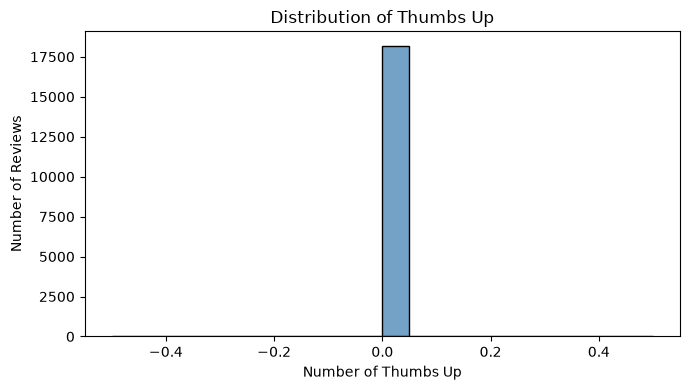

In [74]:
# Visualization 4: Thumbs Up Distribution

df['thumbs_up'] = pd.to_numeric(
    df['thumbs_up'], errors='coerce'
)

plt.figure(figsize=(7, 4))

sns.histplot(
    data=df,
    x="thumbs_up",
    bins=20,
    color="steelblue"
)

plt.title("Distribution of Thumbs Up")
plt.xlabel("Number of Thumbs Up")
plt.ylabel("Number of Reviews")

plt.tight_layout()
plt.show()

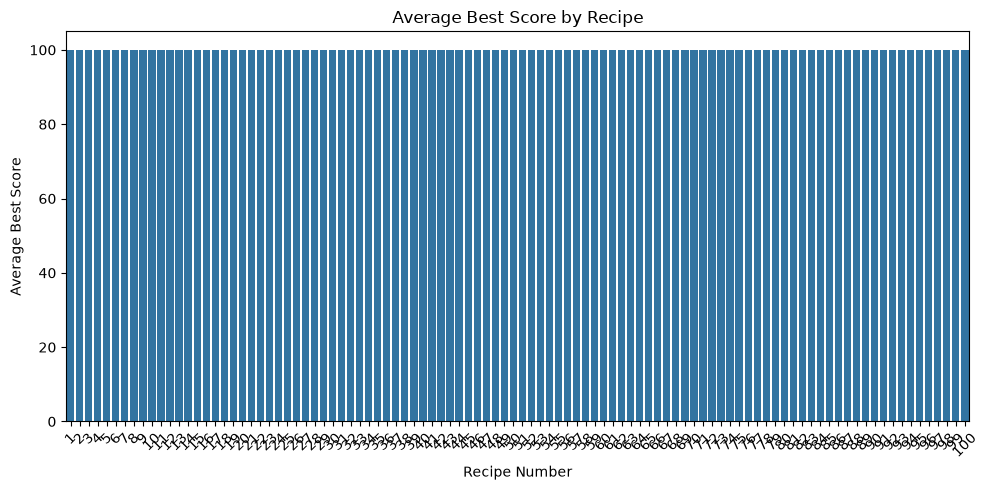

In [77]:
# Visualization 5: Average Best Score by Recipe
plt.figure(figsize=(10, 5))
sns.barplot(
    data=df,
    x="recipe_number",
    y="best_score",
    errorbar=None
)
plt.title("Average Best Score by Recipe")
plt.xlabel("Recipe Number")
plt.ylabel("Average Best Score")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

Column Data Types:
user_reputation    int64
reply_count        int64
thumbs_up          int64
thumbs_down        int64
best_score         int64
stars              int64
dtype: object

Missing Values:
user_reputation    0
reply_count        0
thumbs_up          0
thumbs_down        0
best_score         0
stars              0
dtype: int64

Unique Values:
user_reputation     22
reply_count          4
thumbs_up           62
thumbs_down         58
best_score         588
stars                6
dtype: int64

Correlation Matrix:
                 user_reputation  reply_count  thumbs_up  thumbs_down  \
user_reputation         1.000000     0.010610   0.057863     0.022890   
reply_count             0.010610     1.000000   0.208788     0.327620   
thumbs_up               0.057863     0.208788   1.000000     0.373251   
thumbs_down             0.022890     0.327620   0.373251     1.000000   
best_score              0.137899     0.201306   0.684837     0.215401   
stars                   0.015554   

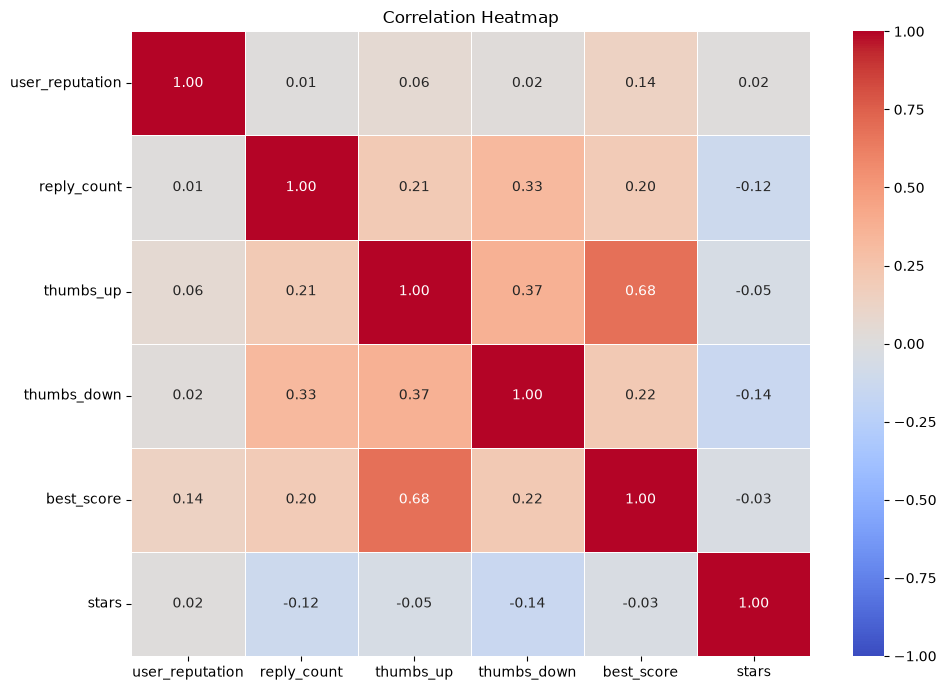

In [82]:
# Visualization 6: Correlation Heatmap
print("Column Data Types:")
print(df[correlation_columns].dtypes)

print("\nMissing Values:")
print(df[correlation_columns].isnull().sum())

print("\nUnique Values:")
print(df[correlation_columns].nunique())

print("\nCorrelation Matrix:")
print(df[correlation_columns].corr())


correlation_columns = [
    "user_reputation",
    "reply_count",
    "thumbs_up",
    "thumbs_down",
    "best_score",
    "stars"
]

# Select available columns
correlation_columns = [
    col for col in correlation_columns
    if col in df.columns
]

# Convert selected columns into numeric format
corr_df = df[correlation_columns].copy()

for col in correlation_columns:
    corr_df[col] = pd.to_numeric(corr_df[col], errors="coerce")

# Calculate correlation
correlation_matrix = corr_df.corr()

# Plot heatmap
plt.figure(figsize=(10, 7))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5,
    vmin=-1,
    vmax=1
)

plt.title("Correlation Heatmap")
plt.tight_layout()
plt.show()

In [84]:
# Import Libraries
import pandas as pd
from sklearn.model_selection import train_test_split

# Load Original Dataset
df = pd.read_csv("Recipe Review.csv")
# Remove Unnecessary Column
df = df.drop(columns=['Unnamed: 0'], errors='ignore')
# Clean Column Names
df.columns = df.columns.str.strip()
# Convert Numeric Columns
numeric_cols = [
    'recipe_number',
    'recipe_code',
    'user_reputation',
    'created_at',
    'reply_count',
    'thumbs_up',
    'thumbs_down',
    'stars',
    'best_score'
]
for col in numeric_cols:
    df[col] = pd.to_numeric(df[col], errors='coerce')
# Handle Missing Text Values
df['text'] = df['text'].fillna('')
# Define Features and Target
target_column = 'stars'
features = [
    'text',
    'user_reputation',
    'reply_count',
    'thumbs_up',
    'thumbs_down'
]
X = df[features]
y = df[target_column]
# Display Target Distribution
print("Target Class Distribution:")
print(y.value_counts().sort_index())
print("\nNumber of Target Classes:", y.nunique())
# Split Dataset into Training and Testing Sets
RANDOM_STATE = 42
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=RANDOM_STATE,
    stratify=y
)
# Display Dataset Shapes
print("\nTraining and Testing Data:")
print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

Target Class Distribution:
stars
0     1696
1      280
2      232
3      490
4     1655
5    13829
Name: count, dtype: int64

Number of Target Classes: 6

Training and Testing Data:
X_train: (14545, 5)
X_test: (3637, 5)
y_train: (14545,)
y_test: (3637,)


In [93]:
# Feature Selection

from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.model_selection import train_test_split
import pandas as pd

# Split Dataset
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=RANDOM_STATE,
    stratify=y
)

# Preprocess Training and Testing Data
X_train_processed = preprocessor.fit_transform(X_train)
X_test_processed = preprocessor.transform(X_test)

# Feature Selection
selector = SelectKBest(score_func=f_classif, k=20)

X_train_selected = selector.fit_transform(
    X_train_processed, y_train
)

X_test_selected = selector.transform(X_test_processed)

# Get Feature Scores
feature_scores = pd.DataFrame({
    'Feature': preprocessor.get_feature_names_out(),
    'Score': selector.scores_,
    'Selected': selector.get_support()
})

feature_scores = feature_scores.sort_values(
    by='Score',
    ascending=False
)

print("Feature Scores:")
print(feature_scores)

print("\nSelected Features:")
print(feature_scores[feature_scores['Selected']]['Feature'])

# Display Dataset Shapes
print("\nTraining set:", X_train.shape)
print("Testing set:", X_test.shape)

print("\nProcessed Training Set:", X_train_selected.shape)
print("Processed Testing Set:", X_test_selected.shape)

print("\nTraining Target Proportions:")
print(y_train.value_counts(normalize=True).round(3))

print("\nTesting Target Proportions:")
print(y_test.value_counts(normalize=True).round(3))

Feature Scores:
                   Feature       Score  Selected
3     numeric__thumbs_down  170.720967      True
4840           text__waste  145.880709      True
3063            text__okay  117.861339      True
608            text__bland  105.629006      True
3062              text__ok  100.797052      True
...                    ...         ...       ...
1262             text__def    0.104396     False
3815   text__sauce perfect    0.103614     False
4771            text__vary    0.102529     False
540          text__begging    0.100631     False
1927      text__good great    0.060317     False

[5004 rows x 3 columns]

Selected Features:
3       numeric__thumbs_down
4840             text__waste
3063              text__okay
608              text__bland
3062                text__ok
4417        text__throw away
1401      text__disappointed
4948             text__worst
460              text__awful
4345          text__terrible
4841        text__waste time
4030             text__sorry
135

In [94]:
# Scaling

X_train_scaled = X_train_selected
X_test_scaled = X_test_selected

print("Training Data Shape:", X_train_scaled.shape)
print("Testing Data Shape:", X_test_scaled.shape)

Training Data Shape: (14545, 20)
Testing Data Shape: (3637, 20)


In [85]:
# Preprocessing

from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.feature_extraction.text import TfidfVectorizer

# Define Numerical and Text Features
numeric_features = [
    'user_reputation',
    'reply_count',
    'thumbs_up',
    'thumbs_down'
]

text_feature = 'text'

# Numerical Preprocessing
numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Text Preprocessing
text_transformer = TfidfVectorizer(
    max_features=5000,
    stop_words='english',
    ngram_range=(1, 2)
)

# Combine Preprocessing Steps
preprocessor = ColumnTransformer(
    transformers=[
        ("numeric", numeric_transformer, numeric_features),
        ("text", text_transformer, text_feature)
    ],
    remainder="drop"
)

print("Numerical features:", numeric_features)
print("Text feature:", text_feature)

Numerical features: ['user_reputation', 'reply_count', 'thumbs_up', 'thumbs_down']
Text feature: text


In [92]:
# Building and Training Classification Models

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    f1_score,
    recall_score
)

# Define Classification Models
models = {
    "Logistic Regression": LogisticRegression(
        max_iter=1000,
        class_weight='balanced'
    ),

    "Decision Tree": DecisionTreeClassifier(
        random_state=42,
        class_weight='balanced'
    ),

    "Random Forest": RandomForestClassifier(
        n_estimators=100,
        random_state=42,
        class_weight='balanced_subsample'
    )
}

# Store Results
scores = []

for name, model in models.items():

    # Train Model
    model.fit(X_train_selected, y_train)

    # Make Predictions
    y_pred = model.predict(X_test_selected)

    # Evaluate Model
    scores.append({
        "Model": name,
        "accuracy": round(accuracy_score(y_test, y_pred), 2),
        "precision": round(precision_score(
            y_test, y_pred, average='weighted', zero_division=0
        ), 2),
        "f1": round(f1_score(
            y_test, y_pred, average='weighted', zero_division=0
        ), 2),
        "recall": round(recall_score(
            y_test, y_pred, average='weighted', zero_division=0
        ), 2)
    })

# Display Results
results_df = pd.DataFrame(scores)
print(results_df.to_string(index=False))

              Model  accuracy  precision   f1  recall
Logistic Regression      0.69       0.63 0.66    0.69
      Decision Tree      0.69       0.65 0.65    0.69
      Random Forest      0.69       0.66 0.66    0.69
